<a href="https://colab.research.google.com/github/anamaciel149/projeto_iris/blob/main/projeto_iris_mvp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação de flores Iris: análise tradicional e Machine Learning

**Disciplina:** Sistemas de Suporte à Decisão | **Ambiente:** Google Colab

**Problema:** é possível identificar a espécie de uma flor a partir de medidas das pétalas e sépalas? Um modelo de inteligência melhora uma regra tradicional de classificação?

**Hipótese:** uma árvore de decisão, ao combinar medidas, pode superar uma regra simples baseada apenas no comprimento da pétala.

**Base:** [Iris, Kaggle](https://www.kaggle.com/datasets/uciml/iris). O conjunto contém 150 flores de três espécies. Não há dados pessoais.

**Perguntas:** (1) Como as espécies se diferenciam nas medidas? (2) Qual é a qualidade dos dados? (3) Uma regra simples consegue classificá-las? (4) O modelo melhora a classificação? (5) Quais medidas são mais úteis?

## 1. Bibliotecas e coleta
A base é obtida diretamente do Kaggle. A célula instala o pacote necessário no Colab.

In [1]:
%pip -q install kagglehub
import os
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATASET = "uciml/iris"
pasta = Path(kagglehub.dataset_download(DATASET))
arquivos = list(pasta.rglob("*.csv"))
if not arquivos:
    raise FileNotFoundError("O download não contém CSV. Confira a página da base no Kaggle.")
caminho = next((p for p in arquivos if p.name.lower() == "iris.csv"), arquivos[0])
dados_brutos = pd.read_csv(caminho)
coleta_utc = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
print("Fonte:", f"https://www.kaggle.com/datasets/{DATASET}")
print("Coleta:", coleta_utc)
print("Arquivo:", caminho.name, "| Registros:", len(dados_brutos), "| Colunas:", len(dados_brutos.columns))
display(dados_brutos.head())

Using Colab cache for faster access to the 'iris' dataset.
Fonte: https://www.kaggle.com/datasets/uciml/iris
Coleta: 2026-10-19 22:22 UTC
Arquivo: Iris.csv | Registros: 150 | Colunas: 6


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 2. Modelagem e catálogo de dados
Será usada uma tabela única (modelo flat). Cada linha representa uma flor. O campo Id, quando presente, é apenas identificador e não será usado para prever a espécie.

In [2]:
df = dados_brutos.copy()
df.columns = df.columns.str.strip()
colunas = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]
faltantes = [c for c in colunas if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas inesperadas na base: {faltantes}")
df = df[colunas].copy()
medidas = colunas[:4]
for c in medidas:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["Species"] = df["Species"].astype("string").str.strip()
print("Formato da tabela analítica:", df.shape)
display(df.head())

Formato da tabela analítica: (150, 5)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
descricoes = {
 "SepalLengthCm":"Comprimento da sépala (cm)",
 "SepalWidthCm":"Largura da sépala (cm)",
 "PetalLengthCm":"Comprimento da pétala (cm)",
 "PetalWidthCm":"Largura da pétala (cm)",
 "Species":"Espécie da flor (variável-alvo)"
}
linhas=[]
for c in colunas:
    dominio = (f"{df[c].min():.2f} a {df[c].max():.2f} cm (observado)" if c in medidas
               else ", ".join(sorted(df[c].dropna().unique().tolist())))
    linhas.append({"Atributo":c,"Tipo":"numérico" if c in medidas else "categórico",
                   "Descrição":descricoes[c],"Domínio observado":dominio,
                   "Nulos":int(df[c].isna().sum()),"Origem/linhagem":f"Kaggle ({DATASET}); seleção e conversão de tipos"})
catalogo = pd.DataFrame(linhas)
display(catalogo)
print("Nota: limites observados não são limites biológicos universais.")

,Atributo,Tipo,Descrição,Domínio observado,Nulos,Origem/linhagem
0,SepalLengthCm,numérico,Comprimento da sépala (cm),4.30 a 7.90 cm (observado),0,Kaggle (uciml/iris); seleção e conversão de tipos
1,SepalWidthCm,numérico,Largura da sépala (cm),2.00 a 4.40 cm (observado),0,Kaggle (uciml/iris); seleção e conversão de tipos
2,PetalLengthCm,numérico,Comprimento da pétala (cm),1.00 a 6.90 cm (observado),0,Kaggle (uciml/iris); seleção e conversão de tipos
3,PetalWidthCm,numérico,Largura da pétala (cm),0.10 a 2.50 cm (observado),0,Kaggle (uciml/iris); seleção e conversão de tipos
4,Species,categórico,Espécie da flor (variável-alvo),"Iris-setosa, Iris-versicolor, Iris-virginica",0,Kaggle (uciml/iris); seleção e conversão de tipos


Nota: limites observados não são limites biológicos universais.


## 3. Qualidade dos dados
Verificamos completude, duplicidade, domínios e valores implausíveis. Flores com medidas não positivas ou campos ausentes não devem entrar na modelagem.

In [4]:
qualidade = pd.DataFrame({
 "campo": colunas,
 "nulos": [int(df[c].isna().sum()) for c in colunas],
 "valores_distintos": [int(df[c].nunique()) for c in colunas]
})
print("Linhas duplicadas (sem Id):", int(df.duplicated().sum()))
print("Medidas menores ou iguais a zero:", int((df[medidas] <= 0).sum().sum()))
print("Distribuição das espécies:")
display(df["Species"].value_counts().rename_axis("Espécie").to_frame("Flores"))
display(qualidade)
# Regra de limpeza: excluir linhas incompletas ou com medidas inválidas.
limpo = df.dropna(subset=colunas).copy()
limpo = limpo[(limpo[medidas] > 0).all(axis=1)].copy()
print("Registros válidos:", len(limpo), "| Registros descartados:", len(df)-len(limpo))
print("Duplicatas não são excluídas automaticamente: flores diferentes podem ter medidas iguais.")

Linhas duplicadas (sem Id): 3
Medidas menores ou iguais a zero: 0
Distribuição das espécies:


,Flores
Espécie,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


,campo,nulos,valores_distintos
0,SepalLengthCm,0,35
1,SepalWidthCm,0,23
2,PetalLengthCm,0,43
3,PetalWidthCm,0,22
4,Species,0,3


Registros válidos: 150 | Registros descartados: 0
Duplicatas não são excluídas automaticamente: flores diferentes podem ter medidas iguais.


## 4. ETL e persistência na nuvem
**Extração:** Kaggle. **Transformação:** seleção, conversão e validação. **Carga:** CSV analítico. No Colab, execute a próxima célula e autorize o Google Drive para manter os arquivos persistidos após a sessão. Sem essa autorização, os arquivos ficam apenas no armazenamento temporário do Colab.

In [5]:
# Executar no Google Colab. O Drive exige autorização da conta.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    destino = Path('/content/drive/MyDrive/MVP_Iris')
    destino.mkdir(parents=True, exist_ok=True)
    limpo.to_csv(destino / 'iris_tratada.csv', index=False)
    catalogo.to_csv(destino / 'catalogo_dados.csv', index=False)
    print('Arquivos persistidos no Google Drive:', destino)
except (ImportError, Exception) as e:
    print('Persistência no Drive não confirmada:', str(e))
    destino = Path('/content/MVP_Iris')
    destino.mkdir(parents=True, exist_ok=True)
    limpo.to_csv(destino / 'iris_tratada.csv', index=False)
    catalogo.to_csv(destino / 'catalogo_dados.csv', index=False)
    print('Cópia local temporária:', destino)
print('Para comprovar a persistência, confira os arquivos no Drive e registre uma captura de tela.')

Mounted at /content/drive
Arquivos persistidos no Google Drive: /content/drive/MyDrive/MVP_Iris
Para comprovar a persistência, confira os arquivos no Drive e registre uma captura de tela.


## 5. Análise tradicional
A análise inicial compara médias e distribuições das quatro medidas por espécie. A sobreposição entre grupos ajuda a entender por que uma única regra pode cometer erros.

SepalLengthCm       SepalWidthCm       PetalLengthCm        \
                         mean   std         mean   std          mean   std   
Species                                                                      
Iris-setosa              5.01  0.35         3.42  0.38          1.46  0.17   
Iris-versicolor          5.94  0.52         2.77  0.31          4.26  0.47   
Iris-virginica           6.59  0.64         2.97  0.32          5.55  0.55   

                PetalWidthCm        
                        mean   std  
Species                             
Iris-setosa             0.24  0.11  
Iris-versicolor         1.33  0.20  
Iris-virginica          2.03  0.27

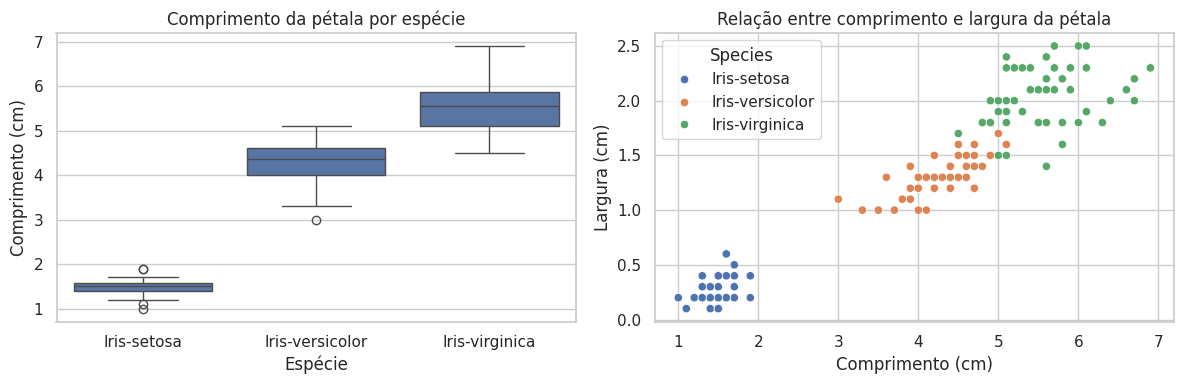

Leitura: verifique quais espécies se separam visualmente e onde há sobreposição.


In [6]:
display(limpo.groupby("Species")[medidas].agg(["mean", "std"]).round(2))
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=limpo, x="Species", y="PetalLengthCm", ax=ax[0])
ax[0].set(title="Comprimento da pétala por espécie", xlabel="Espécie", ylabel="Comprimento (cm)")
sns.scatterplot(data=limpo, x="PetalLengthCm", y="PetalWidthCm", hue="Species", ax=ax[1])
ax[1].set(title="Relação entre comprimento e largura da pétala", xlabel="Comprimento (cm)", ylabel="Largura (cm)")
plt.tight_layout(); plt.show()
print('Leitura: verifique quais espécies se separam visualmente e onde há sobreposição.')

## 6. Separação de treino e teste
Reservamos 25% dos dados para avaliar as duas abordagens nas mesmas flores. Os limites da regra tradicional serão definidos somente com o treino.

In [7]:
X = limpo[medidas]
y = limpo["Species"].astype(str)
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print('Treino:', len(X_treino), '| Teste:', len(X_teste))

Treino: 112 | Teste: 38


## 7. Regra tradicional
Usaremos apenas o comprimento da pétala. Para evitar escolher limites olhando os dados de teste, calculamos dois pontos médios entre as medianas das três espécies no conjunto de treino.

In [8]:
medianas = X_treino.assign(Species=y_treino).groupby('Species')['PetalLengthCm'].median().sort_values()
especies = medianas.index.tolist()
limite1 = (medianas.iloc[0] + medianas.iloc[1])/2
limite2 = (medianas.iloc[1] + medianas.iloc[2])/2
def regra_tradicional(comprimento):
    return np.where(comprimento < limite1, especies[0], np.where(comprimento < limite2, especies[1], especies[2]))
pred_regra = regra_tradicional(X_teste['PetalLengthCm'])
print('Medianas no treino:'); display(medianas.to_frame('Mediana (cm)'))
print(f'Limites da regra: {limite1:.2f} cm e {limite2:.2f} cm')

Medianas no treino:


,Mediana (cm)
Species,
Iris-setosa,1.5
Iris-versicolor,4.3
Iris-virginica,5.6


Limites da regra: 2.90 cm e 4.95 cm


## 8. Mecanismo de inteligência
A árvore de decisão combina as quatro medidas para criar regras de classificação. Limitamos sua profundidade para manter o modelo simples e interpretável.

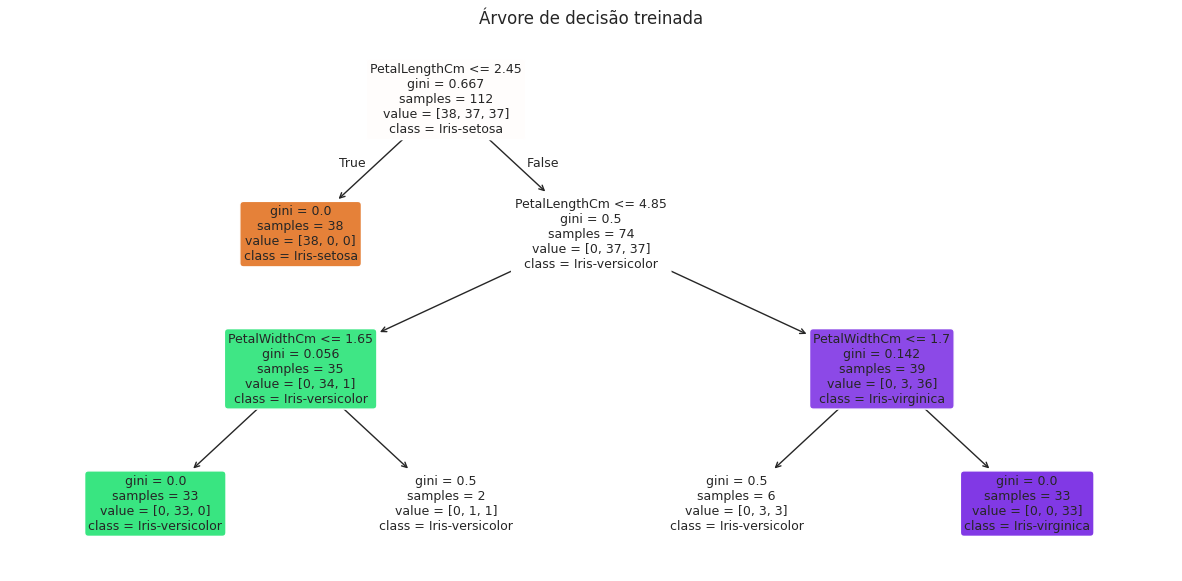

In [9]:
modelo = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
modelo.fit(X_treino, y_treino)
pred_ml = modelo.predict(X_teste)
plt.figure(figsize=(15,7))
plot_tree(modelo, feature_names=medidas, class_names=modelo.classes_, filled=True, rounded=True, fontsize=9)
plt.title('Árvore de decisão treinada'); plt.show()

## 9. Comparação objetiva
Acurácia mede acertos gerais. Precisão e recall macro calculam a média entre as espécies. F1 macro resume o equilíbrio entre precisão e recall. A comparação usa exatamente o mesmo conjunto de teste.

,Acurácia,Precisão macro,Recall macro,F1 macro
Abordagem,,,,
Regra tradicional,0.895,0.903,0.897,0.897
Árvore de decisão,0.895,0.903,0.897,0.897


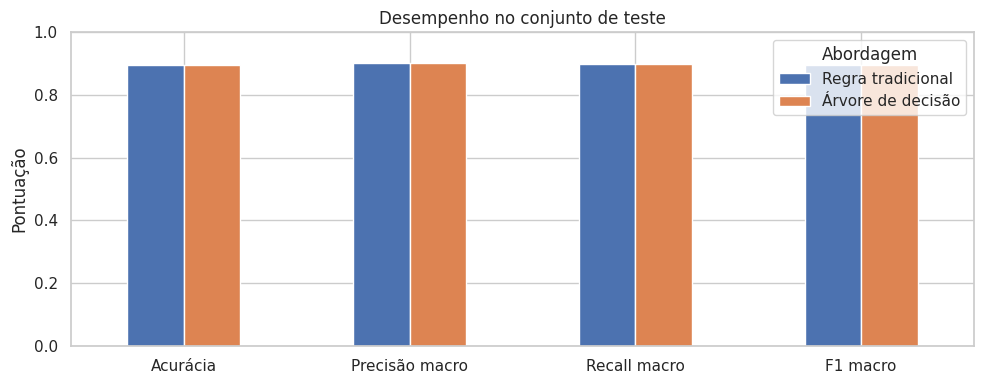

Diferença de acurácia (modelo - regra): +0.000
Interpretação: Houve empate em acurácia.


In [10]:
def avaliar(nome, previsto):
    return {'Abordagem':nome,
            'Acurácia':accuracy_score(y_teste, previsto),
            'Precisão macro':precision_score(y_teste, previsto, average='macro', zero_division=0),
            'Recall macro':recall_score(y_teste, previsto, average='macro', zero_division=0),
            'F1 macro':f1_score(y_teste, previsto, average='macro', zero_division=0)}
comparacao = pd.DataFrame([avaliar('Regra tradicional', pred_regra), avaliar('Árvore de decisão', pred_ml)]).set_index('Abordagem')
display(comparacao.round(3))
comparacao.T.plot(kind='bar', figsize=(10,4), ylim=(0,1), rot=0, title='Desempenho no conjunto de teste')
plt.ylabel('Pontuação'); plt.legend(title='Abordagem'); plt.tight_layout(); plt.show()
print('Diferença de acurácia (modelo - regra):', f"{comparacao.loc['Árvore de decisão','Acurácia']-comparacao.loc['Regra tradicional','Acurácia']:+.3f}")
print('Interpretação:', 'O modelo melhorou a acurácia.' if comparacao.loc['Árvore de decisão','Acurácia'] > comparacao.loc['Regra tradicional','Acurácia'] else ('Houve empate em acurácia.' if comparacao.loc['Árvore de decisão','Acurácia'] == comparacao.loc['Regra tradicional','Acurácia'] else 'A regra tradicional teve maior acurácia.'))

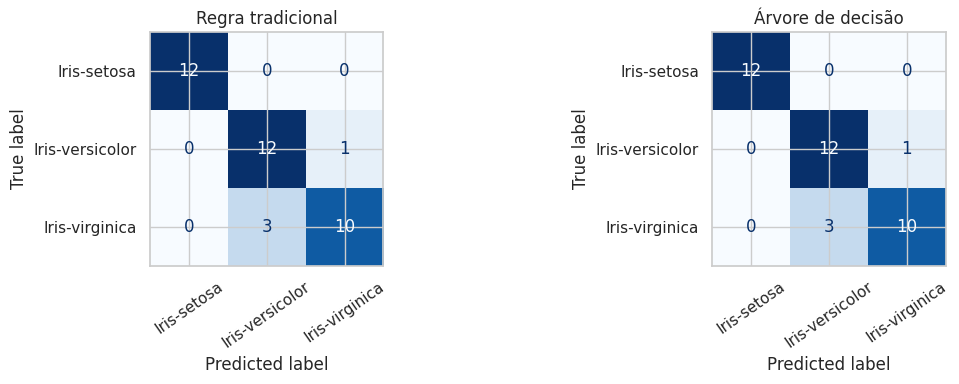

Classificação por espécie (modelo):
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        12
Iris-versicolor       0.80      0.92      0.86        13
 Iris-virginica       0.91      0.77      0.83        13

       accuracy                           0.89        38
      macro avg       0.90      0.90      0.90        38
   weighted avg       0.90      0.89      0.89        38



In [11]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
rotulos = sorted(y.unique())
ConfusionMatrixDisplay.from_predictions(y_teste, pred_regra, labels=rotulos, ax=axes[0], cmap='Blues', colorbar=False, xticks_rotation=35)
axes[0].set_title('Regra tradicional')
ConfusionMatrixDisplay.from_predictions(y_teste, pred_ml, labels=rotulos, ax=axes[1], cmap='Blues', colorbar=False, xticks_rotation=35)
axes[1].set_title('Árvore de decisão')
plt.tight_layout(); plt.show()
print('Classificação por espécie (modelo):')
print(classification_report(y_teste, pred_ml, zero_division=0))

## 10. O que o modelo utilizou?
A importância das variáveis mostra quais medidas a árvore efetivamente usou para separar as espécies. Importância preditiva não significa causalidade.

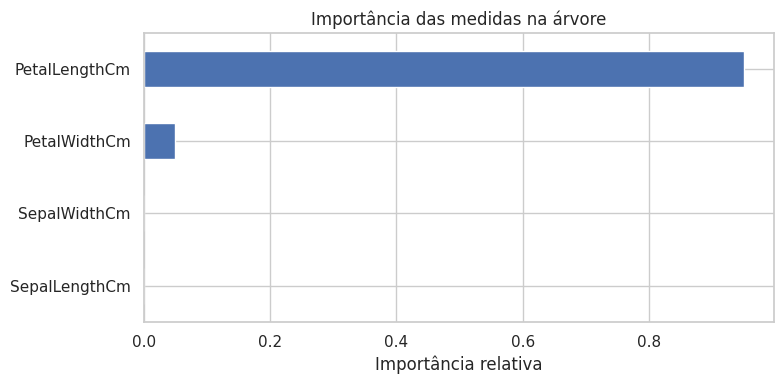

,Importância
PetalLengthCm,0.951
PetalWidthCm,0.049
SepalWidthCm,0.000
SepalLengthCm,0.000


In [12]:
importancias = pd.Series(modelo.feature_importances_, index=medidas).sort_values()
importancias.plot(kind='barh', figsize=(8,4), title='Importância das medidas na árvore')
plt.xlabel('Importância relativa'); plt.tight_layout(); plt.show()
display(importancias.sort_values(ascending=False).to_frame('Importância').round(3))

## 11. Perguntas e respostas por pares
As respostas abaixo são geradas pelos resultados do próprio notebook, sem assumir previamente que o Machine Learning será melhor.

In [13]:
mais_longa = limpo.groupby('Species')['PetalLengthCm'].mean().idxmax()
melhor = comparacao['F1 macro'].idxmax()
respostas = pd.DataFrame([
 {'Pergunta':'Quais espécies têm medidas diferentes?', 'Análise tradicional':'Médias, boxplot e dispersão mostram diferenças e sobreposições.', 'Machine Learning':'A árvore usa divisões nas medidas para distinguir as espécies.'},
 {'Pergunta':'Qual espécie tem maior comprimento médio de pétala?', 'Análise tradicional':f'{mais_longa}, segundo as médias da base.', 'Machine Learning':'Não é necessário usar ML para responder a uma média.'},
 {'Pergunta':'É possível classificar uma nova flor?', 'Análise tradicional':'Sim, pela regra de comprimento da pétala.', 'Machine Learning':'Sim, combinando medidas na árvore.'},
 {'Pergunta':'Qual abordagem teve melhor F1 macro no teste?', 'Análise tradicional':f"{comparacao.loc['Regra tradicional','F1 macro']:.3f}", 'Machine Learning':f"{comparacao.loc['Árvore de decisão','F1 macro']:.3f}. Melhor resultado: {melhor}."}
])
display(respostas)
print('Conclusão: as análises descritivas continuam úteis para explicar diferenças entre grupos; o ganho preditivo depende das métricas observadas no teste.')

,Pergunta,Análise tradicional,Machine Learning
0,Quais espécies têm medidas diferentes?,"Médias, boxplot e dispersão mostram diferenças...",A árvore usa divisões nas medidas para disting...
1,Qual espécie tem maior comprimento médio de pé...,"Iris-virginica, segundo as médias da base.",Não é necessário usar ML para responder a uma ...
2,É possível classificar uma nova flor?,"Sim, pela regra de comprimento da pétala.","Sim, combinando medidas na árvore."
3,Qual abordagem teve melhor F1 macro no teste?,0.897,0.897. Melhor resultado: Regra tradicional.


Conclusão: as análises descritivas continuam úteis para explicar diferenças entre grupos; o ganho preditivo depende das métricas observadas no teste.


## 12. Conclusão e autoavaliação
**Objetivo atingido:** a base foi coletada, tratada, analisada e usada para comparar uma regra manual com uma árvore de decisão. As quatro perguntas foram respondidas.

**Limitações:** a base é pequena e clássica; um único corte treino/teste pode variar conforme a amostra. Não há comprovação de que resultados se repetirão em outras bases.

**Próximos passos:** testar validação cruzada e novas bases, mantendo uma comparação justa.

**Evidências para o professor:** apresente os gráficos, a tabela de métricas, as matrizes de confusão e a pasta no Google Drive após executar a célula de persistência. A captura da pasta no Drive deve ser feita na sua conta.

**Licenciamento:** consulte a licença exibida na página do Kaggle antes de republicar dados brutos. O repositório pode conter apenas o notebook e o README, baixando a base na execução.